# 🍔 TPI Python: Pipeline ETL de Food Delivery (EE.UU.)

Pipeline ETL para una startup de delivery que quiere expandirse en Estados Unidos: leo los datos crudos de restaurantes y menús, los limpio, los cargo en una base SQLite y respondo las preguntas del CEO con SQL y gráficos.

In [21]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text   # para la fase LOAD (SQLite)

## 📥 EXTRACT

In [22]:
# reviso que los archivos estén en la carpeta data
print(os.listdir("data"))

['restaurant_menus_parte_3.csv', 'restaurants.csv', 'restaurant_menus_parte_2.csv', 'restaurant_menus_parte_8.csv', 'restaurant_menus_parte_9.csv', 'restaurant_menus_parte_10.csv', 'restaurant_menus_parte_4.csv', 'restaurant_menus_parte_6.csv', 'restaurant_menus_parte_1.csv', 'restaurant_menus_parte_7.csv', 'restaurant_menus_parte_5.csv']


In [23]:
df_restaurantes = pd.read_csv("data/restaurants.csv")

# los menús vienen en 10 partes: las leo todas y las uno en un solo dataframe
# (no uso la columna description)
archivos_menus = glob.glob("data/restaurant_menus_parte_*.csv")
partes_menus = [pd.read_csv(archivo, usecols=["restaurant_id", "category", "name", "price"]) for archivo in archivos_menus]
df_menus = pd.concat(partes_menus, ignore_index=True)

print("Archivos de menús leídos:", len(archivos_menus))

Archivos de menús leídos: 10


In [24]:
# diagnóstico inicial de las dos tablas
for nombre, df in [("df_restaurantes", df_restaurantes), ("df_menus", df_menus)]:
    print(nombre)
    print("Dimensiones:", df.shape)
    print(df.dtypes)
    print(df.isnull().sum())
    print()

df_restaurantes
Dimensiones: (63469, 11)
id                int64
position          int64
name             object
score           float64
ratings         float64
category         object
price_range      object
full_address     object
zip_code         object
lat             float64
lng             float64
dtype: object
id                  0
position            0
name                0
score           28167
ratings         28167
category           85
price_range     10617
full_address      453
zip_code          517
lat                 0
lng                 0
dtype: int64

df_menus
Dimensiones: (836350, 4)
restaurant_id     int64
category         object
name             object
price            object
dtype: object
restaurant_id    0
category         0
name             1
price            0
dtype: int64



## 🧹 TRANSFORM

### Restaurantes

In [25]:
# rango de precios: de símbolos a texto
mapa_precios = {"$": "Económico", "$$": "Moderadamente caro", "$$$": "Caro", "$$$$": "Muy caro"}

df_restaurantes = df_restaurantes.rename(columns={"price_range": "rango_de_precios"})
df_restaurantes["rango_de_precios"] = df_restaurantes["rango_de_precios"].map(mapa_precios)
# los que no tienen rango los dejo como "No especificado" para no perderlos
df_restaurantes["rango_de_precios"] = df_restaurantes["rango_de_precios"].fillna("No especificado")

df_restaurantes["rango_de_precios"].value_counts()

,count
rango_de_precios,
Económico,37637
Moderadamente caro,14952
No especificado,10618
Caro,237
Muy caro,25


In [26]:
# la dirección viene como "calle, ciudad, estado, zip".
# separo desde la derecha por si la calle trae comas propias
partes = df_restaurantes["full_address"].str.rsplit(",", n=3, expand=True)

df_restaurantes["calle"] = partes[0].str.strip()
df_restaurantes["ciudad"] = partes[1].str.strip()
df_restaurantes["estado_zip"] = partes[2].str.strip() + " " + partes[3].str.strip()

df_restaurantes[["full_address", "calle", "ciudad", "estado_zip"]].head()

,full_address,calle,ciudad,estado_zip
0,"224 Daniel Payne Drive, Birmingham, AL, 35207",224 Daniel Payne Drive,Birmingham,AL 35207
1,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",1521 Pinson Valley Parkway,Birmingham,AL 35217
2,"541-B Graymont Ave, Birmingham, AL, 35204",541-B Graymont Ave,Birmingham,AL 35204
3,"1580 Montgomery Highway, Hoover, AL, 35226",1580 Montgomery Highway,Hoover,AL 35226
4,"314 17th St N, Birmingham, AL, 35203",314 17th St N,Birmingham,AL 35203


In [27]:
# me quedo solo con restaurantes que tengan score válido
filas_antes = len(df_restaurantes)
df_restaurantes = df_restaurantes[df_restaurantes["score"].notna() & (df_restaurantes["score"] > 0)].copy()
df_restaurantes["category"] = df_restaurantes["category"].str.lower()

print(f"Restaurantes: {filas_antes} -> {len(df_restaurantes)}")

Restaurantes: 63469 -> 35302


### Menús

In [28]:
# el precio viene como texto (ej. "6.99 USD"): quito " USD" y lo paso a número
df_menus["price"] = df_menus["price"].str.replace(" USD", "", regex=False).str.replace(",", ".", regex=False)
df_menus["price"] = pd.to_numeric(df_menus["price"], errors="coerce")

# fuera los platos con precio nulo o 0
filas_antes = len(df_menus)
df_menus = df_menus[df_menus["price"].notna() & (df_menus["price"] > 0)]

print(f"Platos: {filas_antes} -> {len(df_menus)}")
print(df_menus["price"].dtype)

Platos: 836350 -> 798797
float64


### Filtro de consolidados y cruce de tablas

In [29]:
# solo restaurantes consolidados (más de 100 calificaciones) para no cargar tanta memoria
df_restaurantes = df_restaurantes[df_restaurantes["ratings"] > 100]
df_restaurantes = df_restaurantes.drop_duplicates(subset="id")

# inner join: id (restaurantes) con restaurant_id (menús)
df_master = pd.merge(df_restaurantes, df_menus, left_on="id", right_on="restaurant_id",
                     how="inner", suffixes=("_restaurante", "_menu"))
df_master = df_master.drop(columns="restaurant_id")

print("df_master:", df_master.shape)
print("Restaurantes consolidados con menú:", df_master["id"].nunique(), "de", len(df_restaurantes))
df_master.head()

df_master: (63221, 17)
Restaurantes consolidados con menú: 671 de 8702


,id,position,name_restaurante,score,ratings,category_restaurante,rango_de_precios,full_address,zip_code,lat,lng,calle,ciudad,estado_zip,category_menu,name_menu,price
0,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,WI 53221,Picked for you,Spring Roll,6.99
1,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,WI 53221,Picked for you,Egg Roll,6.50
2,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,WI 53221,Picked for you,Grilled Pork,9.50
3,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,WI 53221,Picked for you,House Special,10.95
4,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,WI 53221,Picked for you,Rice Noodle with Rare Steak,10.95


## 💾 LOAD

In [30]:
engine = create_engine("sqlite:///delivery_insights.db")
df_master.to_sql("master_food_data", engine, if_exists="replace", index=False)

# compruebo que se cargó
with engine.connect() as conn:
    print(pd.read_sql(text("SELECT COUNT(*) AS filas FROM master_food_data"), conn))

   filas
0  63221


## 📊 BI: reporte para el CEO

Cada restaurante aparece una vez por cada plato de su menú, por eso para contar restaurantes uso `COUNT(DISTINCT id)`.

In [31]:
conn = engine.connect()

## 1️⃣ Penetración geográfica
**¿Cuáles son las 5 ciudades con más restaurantes consolidados?**

In [32]:
query1 = """
SELECT ciudad, COUNT(DISTINCT id) AS total_restaurantes
FROM master_food_data
WHERE ciudad IS NOT NULL
GROUP BY ciudad
ORDER BY total_restaurantes DESC
LIMIT 5
"""
df_q1 = pd.read_sql(text(query1), conn)
df_q1

,ciudad,total_restaurantes
0,Milwaukee,123
1,Seattle,119
2,Lynnwood,42
3,Everett,32
4,Bellevue,30


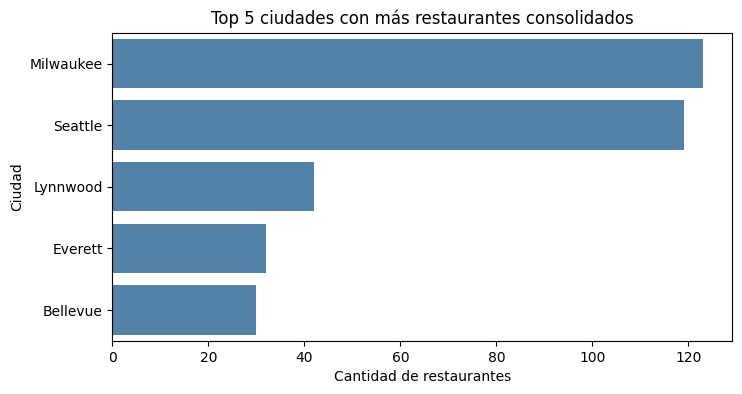

In [33]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df_q1, x="total_restaurantes", y="ciudad", color="steelblue")
plt.title("Top 5 ciudades con más restaurantes consolidados")
plt.xlabel("Cantidad de restaurantes")
plt.ylabel("Ciudad")
plt.show()

**Conclusión para el CEO: **El mercado con mayor cantidad de restaurantes consolidados está liderado por Milwaukee y Seattle, seguidas por Lynnwood, Everett y Bellevue. Milwaukee se ubica en el primer lugar superando los 120 restaurantes.**

## 2️⃣ Oportunidad de precio
**¿Cómo se distribuyen realmente los rangos de precio?**



In [34]:
query2 = """
SELECT rango_de_precios, COUNT(DISTINCT id) AS total_restaurantes
FROM master_food_data
GROUP BY rango_de_precios
ORDER BY total_restaurantes DESC
"""
df_q2 = pd.read_sql(text(query2), conn)
df_q2["porcentaje"] = (df_q2["total_restaurantes"] / df_q2["total_restaurantes"].sum() * 100).round(1)
df_q2

,rango_de_precios,total_restaurantes,porcentaje
0,Económico,450,67.1
1,Moderadamente caro,157,23.4
2,No especificado,60,8.9
3,Caro,4,0.6


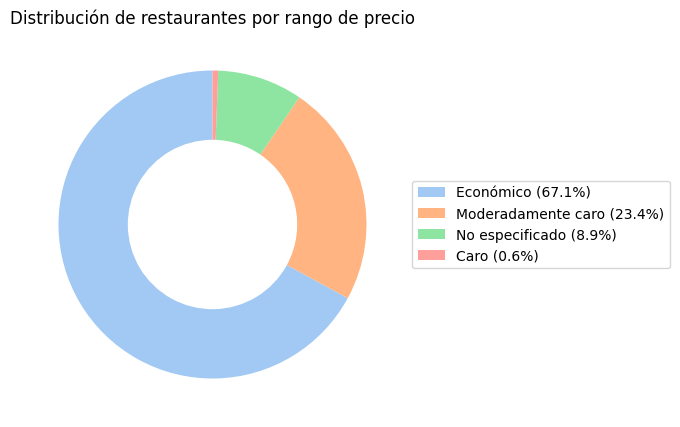

In [35]:
etiquetas = [f"{rango} ({pct}%)" for rango, pct in zip(df_q2["rango_de_precios"], df_q2["porcentaje"])]

plt.figure(figsize=(8, 5))
plt.pie(df_q2["total_restaurantes"], startangle=90, colors=sns.color_palette("pastel"),
        wedgeprops={"width": 0.45})
plt.legend(etiquetas, loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Distribución de restaurantes por rango de precio")
plt.show()

**Conclusión para el CEO: **En el gráfico se puede apreciar que la mayoría de los restaurantes del mercado son económicos, representando más del 50% con un 67.1%, frente a los de precio caro que alcanzan el 23.4%.**

### 3️⃣ Precio promedio de los platos en las 3 ciudades con más restaurantes

In [36]:
query3 = """
SELECT ciudad, ROUND(AVG(price), 2) AS precio_promedio
FROM master_food_data
WHERE ciudad IN (
    SELECT ciudad
    FROM master_food_data
    WHERE ciudad IS NOT NULL
    GROUP BY ciudad
    ORDER BY COUNT(DISTINCT id) DESC
    LIMIT 3
)
GROUP BY ciudad
ORDER BY precio_promedio DESC
"""
df_q3 = pd.read_sql(text(query3), conn)
df_q3

,ciudad,precio_promedio
0,Seattle,11.98
1,Lynnwood,10.76
2,Milwaukee,9.52


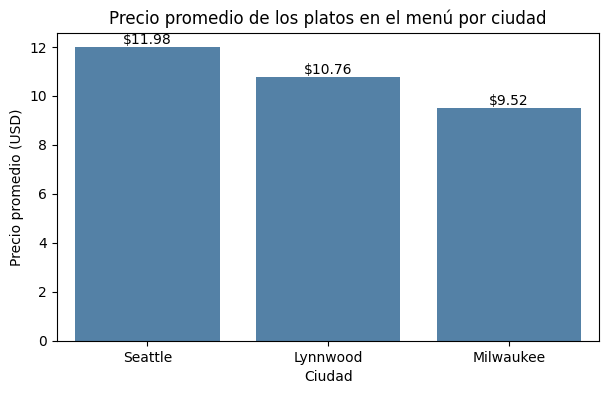

In [44]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df_q3, x="ciudad", y="precio_promedio", color="steelblue")
ax.bar_label(ax.containers[0], fmt="$%.2f")
plt.title("Precio promedio de los platos en el menú por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Precio promedio (USD)")
plt.show()

**Conclusión para el CEO: **Al analizar el precio promedio de los platos en las tres ciudades principales, se identifica que Seattle registra el costo más alto con (11.98),convirtiéndose en la ciudad donde es más caro comer, mientras que Lynnwood se sitúa en un promedio de (10.76( y Milwaukee en (9.52).**

### 4️⃣ ¿Un restaurante más caro garantiza mejor calidad?

In [38]:
# uso DISTINCT para que cada restaurante cuente una sola vez (si no, pesan más los que tienen más platos)
query4 = """
SELECT rango_de_precios, ROUND(AVG(score), 2) AS score_promedio, COUNT(*) AS total_restaurantes
FROM (
    SELECT DISTINCT id, rango_de_precios, score
    FROM master_food_data
    WHERE rango_de_precios <> 'No especificado'
) AS restaurantes_unicos
GROUP BY rango_de_precios
ORDER BY CASE rango_de_precios
    WHEN 'Económico' THEN 1
    WHEN 'Moderadamente caro' THEN 2
    WHEN 'Caro' THEN 3
    WHEN 'Muy caro' THEN 4
END
"""
df_q4 = pd.read_sql(text(query4), conn)
df_q4

,rango_de_precios,score_promedio,total_restaurantes
0,Económico,4.62,450
1,Moderadamente caro,4.64,157
2,Caro,4.45,4


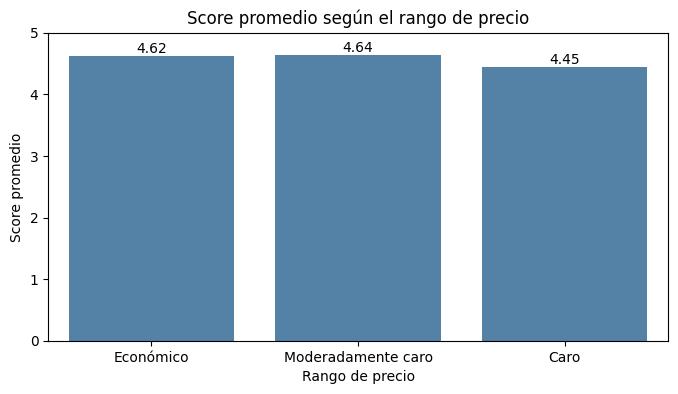

In [39]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=df_q4, x="rango_de_precios", y="score_promedio", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.ylim(0, 5)
plt.title("Score promedio según el rango de precio")
plt.xlabel("Rango de precio")
plt.ylabel("Score promedio")
plt.show()

**Conclusión para el CEO:** _Los datos demuestran que un precio más elevado no garantiza una mayor satisfacción del usuario. Los restaurantes económicos (4.62) y moderadamente caros (4.64) obtienen calificaciones promedio más altas que la categoría de precio caro, la cual registra la puntuación más baja del mercado con 4.45._

In [40]:
conn.close()

## 📝 Resumen y conclusión general


**Hallazgos principales:**
1. _El mercado está liderado por Milwaukee y Seattle, que concentran la mayor cantidad de restaurantes consolidados (superando los 115 locales cada una), seguidas por Lynnwood, Everett y Bellevue._
2. _Existe una clara predominancia del segmento accesible; la mayoría de los restaurantes del mercado son económicos, representando más de la mitad (67.1%), frente a un 23.4% que corresponden a la categoría de precios caros._
3. _Al analizar el costo promedio de los menús en las ciudades principales, Seattle se posiciona como la ciudad donde es más caro comer en promedio, registrando un valor de $11.98 por plato._
4. _Queda demostrado que un precio más alto no garantiza una mejor experiencia. Los restaurantes económicos y moderadamente caros obtienen calificaciones promedio superiores (4.62 y 4.64, respectivamente), superando ligeramente al segmento de precios caros (4.45)._

